# Object Image Classifier: Transfer Learning vs. Training From Scratch
**COMP 365 Individual Project · Practical Checkpoint 2 (testing)** · Ryan Kevena

**Question.** On low-resolution (32×32) photos of everyday objects and animals (CIFAR-10), how much does fine-tuning an ImageNet-pretrained ResNet-18 improve test accuracy over the same ResNet-18 trained from scratch, and how does that gap change as the number of training images grows?

**What is new since Checkpoint 1**
1. Every setting is repeated with **2 random seeds** (different training subsets and initializations), so results are reported as mean ± standard deviation. A third seed is planned.
2. Two **simpler baselines** are added and tested on the same 10,000 test images: logistic regression on raw pixels, and a *linear probe* (logistic regression on frozen, not fine-tuned, ImageNet features).
3. **Statistical tests**: bootstrap 95% confidence intervals and a paired McNemar test (fine-tuned vs. scratch on the same test images).
4. **Failure analysis**: confusion pairs, the most confident mistakes, and per-class accuracy across seeds.
5. **Web-app test**: `app.py` is launched as a real server and queried through its API on 50 test images.

**How to run (Google Colab):** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all` (a few minutes on a GPU). The executed copy in this submission ran on a single CPU core; because the 16 training runs take about 45 minutes there, each finished run is saved to `outputs/runs/` and reused if the notebook is re-run.

In [1]:
# ---- Experiment settings ----
SIZES = [500, 1000, 2500, 5000]   # balanced training-set sizes (50 / 100 / 250 / 500 per class)
SEEDS = [0, 1]                    # Checkpoint 1 used one seed; Checkpoint 2 uses two (a third is planned)
TRAIN_STEPS = 200                 # same number of optimizer steps for every run (fixed compute budget)
BATCH_SIZE = 64
IMG_SIZE = 64                     # 32x32 images upsampled 2x so the ImageNet filters apply better
LR = {"scratch": 0.05, "finetune": 0.01}
WEIGHT_DECAY = 5e-4
OUT_DIR = "outputs"
TEST_WEB_APP = True               # launch app.py and query it (section 9)

In [2]:
import os, time, random, glob, io, zipfile, urllib.request, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision.models import resnet18
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from scipy.stats import chi2
from PIL import Image

os.makedirs(OUT_DIR, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
torch.backends.cudnn.benchmark = True
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", device)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

PyTorch 2.5.1+cu124 | torchvision 0.20.1+cu124 | device: cpu


## 1. Data: CIFAR-10
The notebook first tries the official CIFAR-10 download through `torchvision`. If that host is unreachable (as it was in the environment that executed this copy), it falls back to a public GitHub mirror of the same 60,000 images stored as JPEG files (`YoongiKim/CIFAR-10-images`). The mirror has the same images, classes and train/test split, but light JPEG compression; section 8 measures how much that changes accuracy.

In [3]:
CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

def load_official():
    tr = torchvision.datasets.CIFAR10(root="data", train=True, download=True)
    te = torchvision.datasets.CIFAR10(root="data", train=False, download=True)
    return tr.data, np.array(tr.targets), te.data, np.array(te.targets)

def load_mirror():
    cache = "data/cifar10_mirror.npz"
    if os.path.exists(cache):
        d = np.load(cache); return d["Xtr"], d["ytr"], d["Xte"], d["yte"]
    root = "CIFAR-10-images-master"
    if not os.path.isdir(root):
        url = "https://codeload.github.com/YoongiKim/CIFAR-10-images/zip/refs/heads/master"
        zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())).extractall(".")
    out = []
    for split in ["train", "test"]:
        X, y = [], []
        for c, name in enumerate(CLASSES):
            for f in sorted(glob.glob(f"{root}/{split}/{name}/*.jpg")):
                X.append(np.array(Image.open(f).convert("RGB"))); y.append(c)
        out += [np.stack(X), np.array(y)]
    os.makedirs("data", exist_ok=True)
    np.savez(cache, Xtr=out[0], ytr=out[1], Xte=out[2], yte=out[3])
    return out

try:
    Xtr_np, ytr_np, Xte_np, yte_np = load_official(); DATA_SOURCE = "official CIFAR-10 (torchvision)"
except Exception as e:
    print("Official download unavailable:", type(e).__name__, "-> using GitHub JPEG mirror")
    Xtr_np, ytr_np, Xte_np, yte_np = load_mirror(); DATA_SOURCE = "CIFAR-10 JPEG mirror (GitHub)"

Xtr = torch.tensor(Xtr_np).permute(0, 3, 1, 2).contiguous(); ytr = torch.tensor(ytr_np)
Xte = torch.tensor(Xte_np).permute(0, 3, 1, 2).contiguous(); yte = torch.tensor(yte_np)
print("Data source:", DATA_SOURCE)
print("Train:", tuple(Xtr.shape), "| Test:", tuple(Xte.shape))
print("Train per class:", torch.bincount(ytr).tolist()); print("Test per class: ", torch.bincount(yte).tolist())
# Cleaning check: no missing labels, images all 32x32x3, classes balanced
assert Xtr.shape[1:] == (3, 32, 32) and Xte.shape[1:] == (3, 32, 32)
assert torch.bincount(ytr).min() == 5000 and torch.bincount(yte).min() == 1000

Official download unavailable: HTTPError -> using GitHub JPEG mirror


Data source: CIFAR-10 JPEG mirror (GitHub)
Train: (50000, 3, 32, 32) | Test: (10000, 3, 32, 32)
Train per class: [5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000]
Test per class:  [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


## 2. Balanced subsets and preprocessing (same as Checkpoint 1)

In [4]:
def balanced_subset(labels, n_total, seed=0):
    # Same seed -> same per-class order, so smaller subsets are nested inside larger ones.
    g = torch.Generator().manual_seed(seed)
    idx = []
    for c in range(10):
        cidx = (labels == c).nonzero(as_tuple=True)[0]
        idx.append(cidx[torch.randperm(len(cidx), generator=g)][:n_total // 10])
    return torch.cat(idx)

MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def gpu_augment(x_uint8):
    # Random crop (4px reflect padding) + horizontal flip at 32x32, then upsample and normalize.
    x = x_uint8.float() / 255.0; B = x.size(0)
    x = F.pad(x, (4, 4, 4, 4), mode="reflect")
    i = torch.randint(0, 9, (B,), device=x.device); j = torch.randint(0, 9, (B,), device=x.device)
    ar = torch.arange(32, device=x.device)
    rows = (i[:, None] + ar)[:, None, :, None]; cols = (j[:, None] + ar)[:, None, None, :]
    bi = torch.arange(B, device=x.device)[:, None, None, None]; ci = torch.arange(3, device=x.device)[None, :, None, None]
    x = x[bi, ci, rows, cols]
    flip = torch.rand(B, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    x = F.interpolate(x, size=IMG_SIZE, mode="bilinear", align_corners=False)
    return (x - MEAN) / STD

def prep_eval(x_uint8):
    x = F.interpolate(x_uint8.float() / 255.0, size=IMG_SIZE, mode="bilinear", align_corners=False)
    return (x - MEAN) / STD

for s in SEEDS:
    idx = balanced_subset(ytr, 5000, s)
    print(f"seed {s}: 5,000-image subset, per-class counts {torch.bincount(ytr[idx], minlength=10).tolist()}")

seed 0: 5,000-image subset, per-class counts [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]
seed 1: 5,000-image subset, per-class counts [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]


## 3. Models and training (same recipe as Checkpoint 1)

In [5]:
PRETRAINED_URL = ("https://github.com/huggingface/pytorch-image-models/releases/download/"
                  "v0.1-rsb-weights/resnet18_a1_0-d63eafa0.pth")
IMAGENET_STATE = torch.hub.load_state_dict_from_url(PRETRAINED_URL, map_location="cpu", check_hash=True)

def make_model(kind):
    m = resnet18(weights=None)
    if kind == "finetune":
        m.load_state_dict(IMAGENET_STATE)
    m.fc = nn.Linear(m.fc.in_features, 10)
    return m.to(device).to(memory_format=torch.channels_last)

@torch.no_grad()
def evaluate(model, X=None, bs=500):
    X = Xte if X is None else X
    model.eval(); probs = []
    for k in range(0, len(X), bs):
        xb = prep_eval(X[k:k + bs].to(device)).contiguous(memory_format=torch.channels_last)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            probs.append(F.softmax(model(xb).float(), 1).cpu())
    return torch.cat(probs)

def train_one(kind, n_train, seed):
    set_seed(seed)
    idx = balanced_subset(ytr, n_train, seed)
    Xs, ys = Xtr[idx].to(device), ytr[idx].to(device)
    model = make_model(kind)
    opt = torch.optim.SGD(model.parameters(), lr=LR[kind], momentum=0.9, nesterov=True, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR[kind], total_steps=TRAIN_STEPS, pct_start=0.15)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    model.train(); t0 = time.time()
    for step in range(TRAIN_STEPS):
        b = torch.randint(0, len(idx), (min(BATCH_SIZE, len(idx)),), device=device)
        xb = gpu_augment(Xs[b]).contiguous(memory_format=torch.channels_last)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            loss = F.cross_entropy(model(xb), ys[b], label_smoothing=0.1)
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
    return model, time.time() - t0, loss.item()

## 4. Main experiment: 2 methods × 4 sizes × 2 seeds = 16 training runs, each tested on all 10,000 test images

In [6]:
# Each finished run is saved to outputs/runs/. On a CPU the 16 runs take about 45 minutes, so the notebook
# reuses any run that is already saved (delete outputs/runs/ to retrain everything from scratch).
RUN_DIR = f"{OUT_DIR}/runs"; os.makedirs(RUN_DIR, exist_ok=True)

def run_and_save(kind, n, seed):
    path = f"{RUN_DIR}/{kind}_n{n}_seed{seed}.pt"
    if os.path.exists(path):
        return torch.load(path), True
    model, sec, last_loss = train_one(kind, n, seed)
    probs = evaluate(model); preds = probs.argmax(1)
    rec = dict(method=kind, n_train=n, seed=seed, test_acc=(preds == yte).float().mean().item(),
               macro_f1=f1_score(yte.numpy(), preds.numpy(), average="macro"),
               final_train_loss=last_loss, train_sec=sec, n_test=len(yte), probs=probs.half())
    torch.save(rec, path)
    if kind == "finetune" and n == max(SIZES) and seed == 0:
        torch.save(model.state_dict(), f"{OUT_DIR}/resnet18_finetune_n5000_seed0_cp2.pt")
    return rec, False

results, all_probs = [], {}
for seed in SEEDS:
    for n in SIZES:
        for kind in ["scratch", "finetune"]:
            rec, cached = run_and_save(kind, n, seed)
            all_probs[(kind, n, seed)] = rec.pop("probs")
            results.append(rec)
            print(f"seed {seed} | {kind:>8} | n={n:>5} | acc {rec['test_acc']*100:5.1f}% | macro-F1 {rec['macro_f1']:.3f} | "
                  f"train {rec['train_sec']:4.0f}s{' (saved run)' if cached else ''}", flush=True)
df = pd.DataFrame(results); df.to_csv(f"{OUT_DIR}/cp2_runs.csv", index=False)

seed 0 |  scratch | n=  500 | acc  38.9% | macro-F1 0.386 | train  139s (saved run)


seed 0 | finetune | n=  500 | acc  51.2% | macro-F1 0.508 | train  139s (saved run)


seed 0 |  scratch | n= 1000 | acc  44.4% | macro-F1 0.437 | train  139s (saved run)


seed 0 | finetune | n= 1000 | acc  52.6% | macro-F1 0.524 | train  140s (saved run)


seed 0 |  scratch | n= 2500 | acc  47.1% | macro-F1 0.462 | train  139s (saved run)


...

seed 1 | finetune | n= 1000 | acc  53.7% | macro-F1 0.534 | train  141s (saved run)


seed 1 |  scratch | n= 2500 | acc  44.0% | macro-F1 0.433 | train  140s (saved run)


seed 1 | finetune | n= 2500 | acc  52.8% | macro-F1 0.526 | train  140s (saved run)


seed 1 |  scratch | n= 5000 | acc  46.2% | macro-F1 0.454 | train  140s (saved run)


seed 1 | finetune | n= 5000 | acc  53.4% | macro-F1 0.532 | train  139s (saved run)


## 5. Simpler baselines on the same subsets and the same 10,000 test images
* **Chance / majority class:** 10% (classes are balanced).
* **Pixel logistic regression:** multinomial logistic regression on the 3,072 raw pixel values.
* **Linear probe:** the ImageNet ResNet-18 is *frozen* (not fine-tuned); logistic regression is trained on its 512-number feature vector. This tests whether fine-tuning adds anything beyond reusing the pretrained features.

In [7]:
@torch.no_grad()
def frozen_features(X, bs=500):
    m = resnet18(weights=None); m.load_state_dict(IMAGENET_STATE); m.fc = nn.Identity()
    m = m.to(device).eval(); out = []
    for k in range(0, len(X), bs):
        out.append(m(prep_eval(X[k:k + bs].to(device))).float().cpu())
    return torch.cat(out).numpy()

t0 = time.time()
union = torch.unique(torch.cat([balanced_subset(ytr, max(SIZES), s) for s in SEEDS]))
feat_tr = np.zeros((len(Xtr), 512), np.float32); feat_tr[union.numpy()] = frozen_features(Xtr[union])
feat_te = frozen_features(Xte)
print(f"Frozen ImageNet features: {len(union)} train + {len(Xte)} test images in {time.time()-t0:.0f}s")

pix_te = Xte.reshape(len(Xte), -1).float().numpy() / 255.0
base_rows = []
for seed in SEEDS:
    for n in SIZES:
        idx = balanced_subset(ytr, n, seed).numpy(); y = ytr_np[idx]
        for kind, Xa, Xb, C in [("pixel_logreg", Xtr[idx].reshape(len(idx), -1).float().numpy() / 255.0, pix_te, 0.01),
                                ("linear_probe", feat_tr[idx], feat_te, 0.1)]:
            t1 = time.time()
            sc = StandardScaler().fit(Xa)
            clf = LogisticRegression(C=C, max_iter=300).fit(sc.transform(Xa), y)
            preds = clf.predict(sc.transform(Xb))
            base_rows.append(dict(method=kind, n_train=n, seed=seed, test_acc=(preds == yte_np).mean(),
                                  macro_f1=f1_score(yte_np, preds, average="macro"), train_sec=time.time() - t1, n_test=len(yte_np)))
            if n == max(SIZES): all_probs[(kind, n, seed)] = torch.tensor(clf.predict_proba(sc.transform(Xb))).half()
        print(f"seed {seed} | n={n:>5} | pixel LR {base_rows[-2]['test_acc']*100:5.1f}% | linear probe {base_rows[-1]['test_acc']*100:5.1f}%", flush=True)
df_all = pd.concat([df, pd.DataFrame(base_rows)], ignore_index=True)
df_all.to_csv(f"{OUT_DIR}/cp2_all_runs.csv", index=False)

Frozen ImageNet features: 9510 train + 10000 test images in 95s


seed 0 | n=  500 | pixel LR  28.9% | linear probe  58.9%


seed 0 | n= 1000 | pixel LR  30.1% | linear probe  60.5%


seed 0 | n= 2500 | pixel LR  32.8% | linear probe  62.9%


seed 0 | n= 5000 | pixel LR  34.8% | linear probe  64.6%


seed 1 | n=  500 | pixel LR  28.8% | linear probe  58.7%


seed 1 | n= 1000 | pixel LR  30.0% | linear probe  61.8%


seed 1 | n= 2500 | pixel LR  32.7% | linear probe  61.9%


seed 1 | n= 5000 | pixel LR  34.4% | linear probe  63.1%


## 6. Results: mean ± std over 2 seeds, bootstrap confidence intervals, paired significance test

In [8]:
ORDER = ["finetune", "scratch", "linear_probe", "pixel_logreg"]
NAMES = {"finetune": "Fine-tuned ResNet-18 (ours)", "scratch": "ResNet-18 from scratch",
         "linear_probe": "Linear probe (frozen ImageNet)", "pixel_logreg": "Pixel logistic regression"}
agg = df_all.groupby(["method", "n_train"])["test_acc"].agg(["mean", "std"]) * 100
tab = pd.DataFrame({NAMES[m]: [f"{agg.loc[(m, n), 'mean']:.1f} ± {agg.loc[(m, n), 'std']:.1f}" for n in SIZES] for m in ORDER},
                   index=pd.Index(SIZES, name="training images"))
gap = pd.DataFrame({n: (df[(df.method == "finetune") & (df.n_train == n)].set_index("seed").test_acc
                        - df[(df.method == "scratch") & (df.n_train == n)].set_index("seed").test_acc) * 100 for n in SIZES})
tab["Gap: fine-tuned − scratch (pts)"] = [f"{gap[n].mean():.1f} ± {gap[n].std():.1f}" for n in SIZES]
print("Test accuracy (%) on 10,000 test images, mean ± std over 2 seeds (2 runs per cell). Chance = 10%.")
display(tab); tab.to_csv(f"{OUT_DIR}/cp2_summary_table.csv")

# Bootstrap 95% CI (seed 0, n=5000) and paired McNemar test for every seed at n=5000
rng = np.random.default_rng(0); N = len(yte_np); B = 1000; boots = rng.integers(0, N, (B, N))
rows = []
for m in ORDER:
    for s in SEEDS:
        correct = (all_probs[(m, 5000, s)].float().argmax(1).numpy() == yte_np)
        bs = correct[boots].mean(1) * 100
        rows.append(dict(method=NAMES[m], seed=s, acc=correct.mean() * 100, ci_low=np.percentile(bs, 2.5), ci_high=np.percentile(bs, 97.5)))
ci = pd.DataFrame(rows).round(1); ci.to_csv(f"{OUT_DIR}/cp2_bootstrap_ci_n5000.csv", index=False)
display(ci[ci.seed == 0])

mc = []
for s in SEEDS:
    a = all_probs[("finetune", 5000, s)].float().argmax(1).numpy() == yte_np
    b = all_probs[("scratch", 5000, s)].float().argmax(1).numpy() == yte_np
    b01, b10 = int((a & ~b).sum()), int((~a & b).sum())
    stat = (abs(b01 - b10) - 1) ** 2 / (b01 + b10)
    mc.append(dict(seed=s, only_finetune_right=b01, only_scratch_right=b10, mcnemar_chi2=round(stat, 1), p_value=chi2.sf(stat, 1)))
mc = pd.DataFrame(mc); mc.to_csv(f"{OUT_DIR}/cp2_mcnemar_n5000.csv", index=False)
print("Paired McNemar test, fine-tuned vs. scratch on the same 10,000 test images (n=5,000):"); display(mc)

Test accuracy (%) on 10,000 test images, mean ± std over 2 seeds (2 runs per cell). Chance = 10%.


,Fine-tuned ResNet-18 (ours),ResNet-18 from scratch,Linear probe (frozen ImageNet),Pixel logistic regression,Gap: fine-tuned − scratch (pts)
training images,,,,,
500,51.9 ± 1.0,38.7 ± 0.4,58.8 ± 0.2,28.8 ± 0.1,13.2 ± 1.3
1000,53.1 ± 0.8,44.9 ± 0.7,61.2 ± 0.9,30.1 ± 0.1,8.2 ± 0.1
2500,53.0 ± 0.3,45.5 ± 2.2,62.4 ± 0.7,32.7 ± 0.1,7.5 ± 1.9
5000,53.7 ± 0.5,46.5 ± 0.4,63.8 ± 1.1,34.6 ± 0.3,7.2 ± 0.1


,method,seed,acc,ci_low,ci_high
0,Fine-tuned ResNet-18 (ours),0,54.1,53.0,55.0
2,ResNet-18 from scratch,0,46.8,45.8,47.7
4,Linear probe (frozen ImageNet),0,64.6,63.6,65.6
6,Pixel logistic regression,0,34.8,33.9,35.8


Paired McNemar test, fine-tuned vs. scratch on the same 10,000 test images (n=5,000):


,seed,only_finetune_right,only_scratch_right,mcnemar_chi2,p_value
0,0,2229,1498,143.0,5.926653e-33
1,1,2246,1528,136.2,1.787297e-31


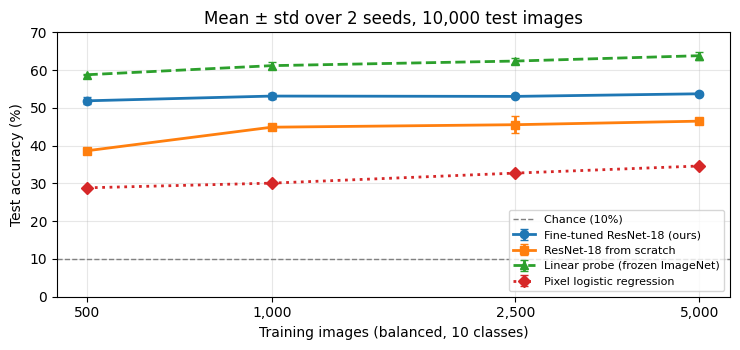

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
styles = {"finetune": ("o", "-"), "scratch": ("s", "-"), "linear_probe": ("^", "--"), "pixel_logreg": ("D", ":")}
for m in ORDER:
    mu = [agg.loc[(m, n), "mean"] for n in SIZES]; sd = [agg.loc[(m, n), "std"] for n in SIZES]
    ax.errorbar(SIZES, mu, yerr=sd, marker=styles[m][0], ls=styles[m][1], lw=2, capsize=3, label=NAMES[m])
ax.axhline(10, color="gray", ls="--", lw=1, label="Chance (10%)")
ax.set_xscale("log"); ax.set_xticks(SIZES); ax.set_xticklabels([f"{n:,}" for n in SIZES]); ax.minorticks_off()
ax.set_ylim(0, 70); ax.set_xlabel("Training images (balanced, 10 classes)"); ax.set_ylabel("Test accuracy (%)")
ax.set_title("Mean ± std over 2 seeds, 10,000 test images"); ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/cp2_results_figure.png", dpi=200); plt.show()

## 7. Weak cases: per-class accuracy, confusion pairs and the most confident mistakes

,finetune_mean,finetune_std,scratch_mean,scratch_std
cls,,,,
cat,40.8,4.5,31.9,9.6
deer,40.8,1.2,24.5,0.8
bird,42.2,0.6,32.8,3.5
dog,48.8,1.8,41.8,1.8
horse,53.4,0.7,57.2,6.1
airplane,56.3,3.0,39.1,3.0
truck,56.7,4.4,53.8,0.9
ship,60.3,2.8,63.2,4.2
frog,67.8,3.2,57.2,4.2


,"count (of 1,000)",true,predicted
0,227,dog,cat
1,221,truck,automobile
2,194,deer,frog
3,187,airplane,ship
4,160,automobile,truck
5,148,cat,dog


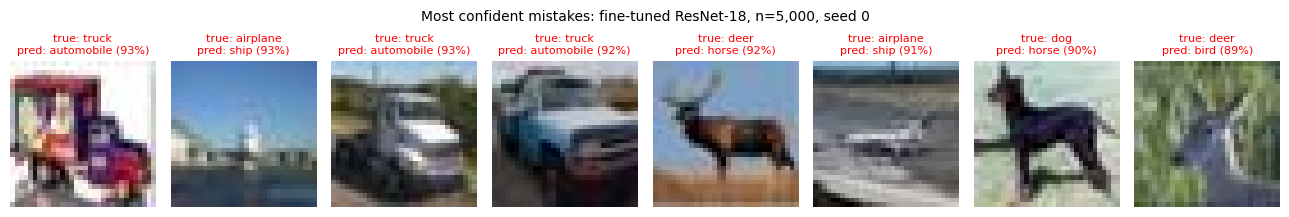

Mean confidence when right: 49.0% | when wrong: 35.5%
Example output, test image 8871 | true: ship | {'ship': 0.976, 'airplane': 0.009, 'truck': 0.004}


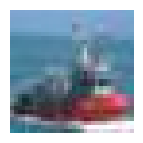

In [10]:
pc = []
for m in ["finetune", "scratch"]:
    for s in SEEDS:
        p = all_probs[(m, 5000, s)].float().argmax(1).numpy()
        for c in range(10):
            pc.append(dict(method=m, cls=CLASSES[c], seed=s, acc=(p[yte_np == c] == c).mean() * 100))
pc = pd.DataFrame(pc).groupby(["cls", "method"]).acc.agg(["mean", "std"]).unstack("method").round(1)
pc.columns = [f"{b}_{a}" for a, b in pc.columns]
pc = pc[["finetune_mean", "finetune_std", "scratch_mean", "scratch_std"]].sort_values("finetune_mean")
display(pc); pc.to_csv(f"{OUT_DIR}/cp2_per_class_n5000.csv")

p0 = all_probs[("finetune", 5000, 0)].float(); pred0 = p0.argmax(1).numpy(); conf0 = p0.max(1).values.numpy()
cm = confusion_matrix(yte_np, pred0)
pairs = sorted([(cm[i, j], CLASSES[i], CLASSES[j]) for i in range(10) for j in range(10) if i != j], reverse=True)[:6]
conf_pairs = pd.DataFrame(pairs, columns=["count (of 1,000)", "true", "predicted"])
display(conf_pairs); conf_pairs.to_csv(f"{OUT_DIR}/cp2_top_confusions.csv", index=False)

wrong = np.where(pred0 != yte_np)[0]; worst = wrong[np.argsort(-conf0[wrong])][:8]
fig, axes = plt.subplots(1, 8, figsize=(13, 2.3))
for ax, i in zip(axes, worst):
    ax.imshow(Xte[i].permute(1, 2, 0)); ax.axis("off")
    ax.set_title(f"true: {CLASSES[yte_np[i]]}\npred: {CLASSES[pred0[i]]} ({conf0[i]*100:.0f}%)", fontsize=8, color="red")
plt.suptitle("Most confident mistakes: fine-tuned ResNet-18, n=5,000, seed 0", fontsize=10)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/cp2_confident_mistakes.png", dpi=170); plt.show()
print(f"Mean confidence when right: {conf0[pred0 == yte_np].mean()*100:.1f}% | when wrong: {conf0[wrong].mean()*100:.1f}%")

# One example output (correct prediction) for the report
right = np.where(pred0 == yte_np)[0]; ex = right[np.argsort(-conf0[right])][3]
top3 = p0[ex].topk(3)
print("Example output, test image", ex, "| true:", CLASSES[yte_np[ex]], "|",
      {CLASSES[i]: round(v.item(), 3) for v, i in zip(top3.values, top3.indices)})
plt.figure(figsize=(1.6, 1.6)); plt.imshow(Xte[ex].permute(1, 2, 0)); plt.axis("off")
plt.savefig(f"{OUT_DIR}/cp2_example_input.png", dpi=150, bbox_inches="tight"); plt.show()
EXAMPLE = dict(index=int(ex), true=CLASSES[yte_np[ex]], top3={CLASSES[i]: round(v.item(), 3) for v, i in zip(top3.values, top3.indices)})

## 8. Data check: does the JPEG mirror change accuracy?
The Checkpoint 1 model (trained on the official CIFAR-10 files, 59.7% on the official test set) is evaluated here on the test set used in this run.

In [11]:
cp1 = resnet18(weights=None); cp1.fc = nn.Linear(512, 10)
cp1.load_state_dict(torch.load(f"{OUT_DIR}/resnet18_finetune_n5000.pt", map_location="cpu")); cp1 = cp1.to(device)
cp1_probs = evaluate(cp1); cp1_acc = (cp1_probs.argmax(1) == yte).float().mean().item() * 100
print(f"Checkpoint 1 model: 59.7% on official test set (Checkpoint 1) vs {cp1_acc:.1f}% on this run's test set ({DATA_SOURCE})")

Checkpoint 1 model: 59.7% on official test set (Checkpoint 1) vs 54.4% on this run's test set (CIFAR-10 JPEG mirror (GitHub))


## 9. Web-app test: launch `app.py` as a server and query it through its API
Test: 50 test images (5 per class) are saved as PNG files and sent to the running Gradio app with `gradio_client`, exactly as a user's upload would be. The app's top-1 answer is compared with the notebook's prediction for the same model (Checkpoint 1 weights) and with the true label.

In [12]:
import subprocess, sys
app_rows = []
if TEST_WEB_APP:
    os.makedirs("app_test", exist_ok=True)
    sel = np.concatenate([np.where(yte_np == c)[0][:5] for c in range(10)])
    for i in sel: Image.fromarray(Xte_np[i]).save(f"app_test/{i}.png")
    server = subprocess.Popen([sys.executable, "app.py", f"{OUT_DIR}/resnet18_finetune_n5000.pt"],
                              stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    try:
        from gradio_client import Client, handle_file
        client = None
        for _ in range(60):
            try: client = Client("http://127.0.0.1:7860/", verbose=False); break
            except Exception: time.sleep(2)
        nb_pred = cp1_probs.argmax(1).numpy()
        for i in sel:
            t1 = time.time(); r = client.predict(handle_file(f"app_test/{i}.png"), api_name="/predict")
            app_rows.append(dict(image=int(i), true=CLASSES[yte_np[i]], app_top1=r["label"], notebook_top1=CLASSES[nb_pred[i]],
                                 app_top3=[c["label"] for c in r["confidences"]], latency_s=time.time() - t1))
    finally:
        server.terminate()
    app_df = pd.DataFrame(app_rows); app_df.to_csv(f"{OUT_DIR}/cp2_webapp_test.csv", index=False)
    print(f"Web-app test on {len(app_df)} uploaded images:")
    print(f"  app top-1 matches notebook prediction: {(app_df.app_top1 == app_df.notebook_top1).mean()*100:.0f}%")
    print(f"  app top-1 accuracy: {(app_df.app_top1 == app_df.true).mean()*100:.0f}% | top-3 accuracy: "
          f"{np.mean([t in a for t, a in zip(app_df.true, app_df.app_top3)])*100:.0f}%")
    print(f"  median response time: {app_df.latency_s.median()*1000:.0f} ms per image")
    display(app_df.head(10))

Web-app test on 50 uploaded images:
  app top-1 matches notebook prediction: 100%
  app top-1 accuracy: 50% | top-3 accuracy: 84%
  median response time: 166 ms per image


,image,true,app_top1,notebook_top1,app_top3,latency_s
0,0,airplane,ship,ship,"[ship, airplane, automobile]",0.234977
1,1,airplane,airplane,airplane,"[airplane, ship, dog]",0.170059
2,2,airplane,airplane,airplane,"[airplane, bird, ship]",0.137742
3,3,airplane,airplane,airplane,"[airplane, horse, deer]",0.178052
4,4,airplane,deer,deer,"[deer, airplane, horse]",0.165819
5,1000,automobile,automobile,automobile,"[automobile, truck, dog]",0.175206
6,1001,automobile,automobile,automobile,"[automobile, truck, ship]",0.167046
7,1002,automobile,truck,truck,"[truck, automobile, airplane]",0.197350
8,1003,automobile,automobile,automobile,"[automobile, truck, ship]",0.112298
9,1004,automobile,automobile,automobile,"[automobile, truck, ship]",0.124053


## 10. Planned tests not yet completed
* Larger training sets (10,000–50,000 images) with a training budget that grows with the data. Not run: the fixed 200-step budget means bigger subsets are under-trained, and a fair budget needs GPU time.
* Testing the web app on real phone photos (outside CIFAR-10).
* A third seed for every setting, and repeating the experiment on the official CIFAR-10 files (this executed copy used the JPEG mirror).

## External data, code, models and AI assistance
* **Data:** CIFAR-10 (Krizhevsky, 2009), https://www.cs.toronto.edu/~kriz/cifar.html; JPEG mirror https://github.com/YoongiKim/CIFAR-10-images
* **Pretrained model:** ResNet-18 ImageNet-1k weights `resnet18_a1_0-d63eafa0.pth` from timm (Wightman, Touvron & Jégou, 2021), https://github.com/huggingface/pytorch-image-models
* **Libraries:** PyTorch, torchvision, NumPy, pandas, Matplotlib, scikit-learn, SciPy, Pillow, Gradio, gradio_client
* **AI-assisted tool:** Claude (Anthropic) was used to help write the notebook code, the web app and the tests.

In [13]:
import shutil, json
json.dump(dict(DATA_SOURCE=DATA_SOURCE, EXAMPLE=EXAMPLE, cp1_acc=cp1_acc), open(f"{OUT_DIR}/cp2_meta.json", "w"))
print(sorted(os.listdir(OUT_DIR)))

['cp2_all_runs.csv', 'cp2_bootstrap_ci_n5000.csv', 'cp2_confident_mistakes.png', 'cp2_example_input.png', 'cp2_mcnemar_n5000.csv', 'cp2_meta.json', 'cp2_per_class_n5000.csv', 'cp2_results_figure.png', 'cp2_runs.csv', 'cp2_summary_table.csv', 'cp2_top_confusions.csv', 'cp2_webapp_test.csv', 'resnet18_finetune_n5000.pt', 'resnet18_finetune_n5000_seed0_cp2.pt', 'runs']
